# Tugas Praktikum 4: Association Rule

**Nama:** Rasya Arya Ramadhan
**NRP:** 5054251019
**Mata Kuliah:** Data Mining (Semester 3)
**Program Studi:** Rekayasa Kecerdasan Artifisial, ITS

Dataset yang digunakan adalah **Online Retail** dari UCI Machine Learning Repository, berisi transaksi ritel online sebuah toko di Inggris periode Desember 2010 - Desember 2011.


## 1. Unduh dan Import Dataset

Dataset dibaca dengan `pandas.read_excel`. Kolom yang tersedia: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, dan `Country`. Pengecekan awal dilakukan untuk memahami tipe data dan keberadaan nilai kosong.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df_raw = pd.read_excel("Online Retail.xlsx")
print("Shape:", df_raw.shape)
df_raw.head()


Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
print("Jumlah nilai kosong per kolom:")
print(df_raw.isna().sum())
print()
print("Jumlah invoice unik:", df_raw["InvoiceNo"].nunique())
print("Rentang tanggal:", df_raw["InvoiceDate"].min(), "s/d", df_raw["InvoiceDate"].max())


Jumlah nilai kosong per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Jumlah invoice unik: 25900
Rentang tanggal: 2010-12-01 08:26:00 s/d 2011-12-09 12:50:00


## 2. Eksplorasi dan Pembersihan Data

Kolom yang paling relevan untuk association rule adalah `InvoiceNo` (penanda transaksi) dan `Description` (item). Aturan pembersihan yang diterapkan:

1. **Hapus baris dengan `Description` kosong** - item yang tidak diketahui tidak bisa dipakai dalam aturan asosiasi.
2. **Hapus transaksi yang dibatalkan** (`InvoiceNo` diawali huruf `C`) - ini adalah pembatalan/retur, bukan pembelian, sehingga jika dibiarkan akan membentuk pola palsu.
3. **Hapus baris dengan `Quantity` <= 0** - menandakan retur atau entri tidak valid.

Alasan memakai ketiga filter tersebut adalah agar transaksi yang dianalisis benar-benar merepresentasikan pembelian nyata.


In [4]:
before_rows = len(df_raw)
before_inv = df_raw["InvoiceNo"].nunique()

mask_desc = df_raw["Description"].notna()
mask_cancel = ~df_raw["InvoiceNo"].astype(str).str.startswith("C")
mask_qty = df_raw["Quantity"] > 0

df = df_raw[mask_desc & mask_cancel & mask_qty].copy()
df["Description"] = df["Description"].astype(str).str.strip()

after_rows = len(df)
after_inv = df["InvoiceNo"].nunique()

ringkasan = pd.DataFrame({
    "Kondisi": ["Sebelum pembersihan", "Sesudah pembersihan"],
    "Jumlah baris": [before_rows, after_rows],
    "Jumlah invoice": [before_inv, after_inv],
})
ringkasan


,Kondisi,Jumlah baris,Jumlah invoice
0,Sebelum pembersihan,541909,25900
1,Sesudah pembersihan,530693,20136


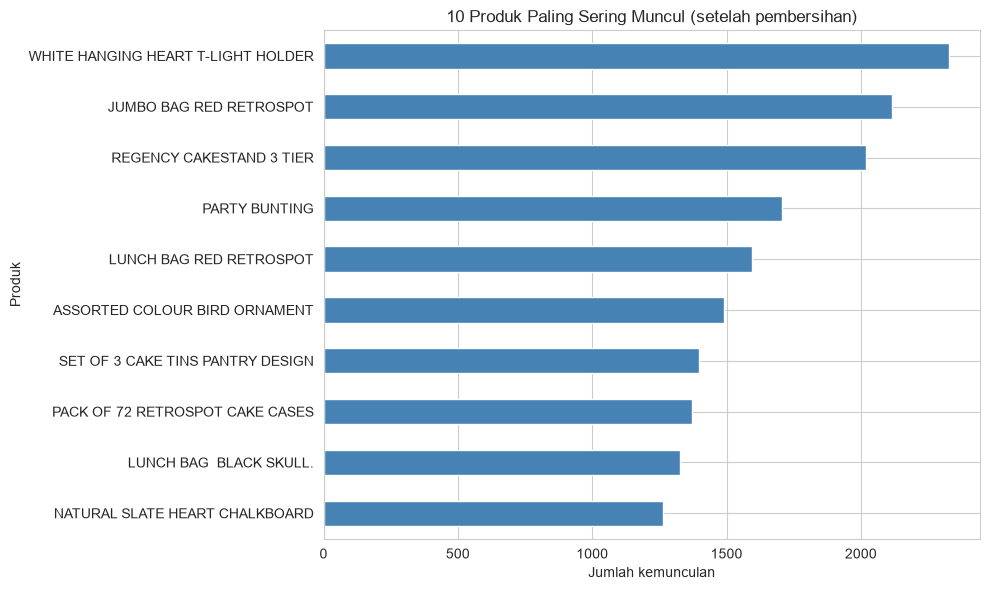

In [5]:
# Visualisasi 10 produk paling sering muncul setelah pembersihan
top_produk = df["Description"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 6))
top_produk[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("10 Produk Paling Sering Muncul (setelah pembersihan)")
ax.set_xlabel("Jumlah kemunculan")
ax.set_ylabel("Produk")
plt.tight_layout()
plt.show()


## 3. Persiapan Data untuk Association Rule

Setiap `InvoiceNo` dianggap satu transaksi (basket). Produk dalam satu invoice yang sama digabung menjadi satu set item, dan duplikat produk dalam invoice yang sama dihilangkan agar satu item tidak dihitung dua kali. Data kemudian diubah ke bentuk one-hot (basket) dengan `TransactionEncoder` dari mlxtend: baris = transaksi, kolom = produk, nilai = True/False.


In [6]:
transactions = (
    df.groupby("InvoiceNo")["Description"]
      .apply(lambda x: list(set(x)))
)
print("Jumlah transaksi:", len(transactions))
print("Rata-rata item per transaksi:", round(transactions.apply(len).mean(), 2))

from mlxtend.preprocessing import TransactionEncoder
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_array, columns=te.columns_)
print("Bentuk basket (transaksi x produk):", basket.shape)
basket.iloc[:5, :8]


Jumlah transaksi: 20136
Rata-rata item per transaksi: 25.82


Bentuk basket (transaksi x produk): (20136, 4065)


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


## 4. Penerapan Algoritma Apriori

Digunakan algoritma **Apriori** karena implementasinya sederhana dan cukup untuk ukuran dataset ini. Ambang awal yang dipakai sesuai ketentuan: minimum support = 0.01 dan minimum confidence = 0.5.

- Minimum support 0.01 berarti item/itemset harus muncul di minimal 1% transaksi.
- Minimum confidence 0.5 berarti aturan hanya diterima jika consequent muncul pada minimal 50% transaksi yang mengandung antecedent.


In [7]:
from mlxtend.frequent_patterns import apriori, association_rules

# Titik awal sesuai ketentuan
fi_awal = apriori(basket, min_support=0.01, use_colnames=True, low_memory=True)
rules_awal = association_rules(fi_awal, metric="confidence", min_threshold=0.5)
print("Frequent itemset awal:", len(fi_awal))
print("Aturan awal (support>=0.01, conf>=0.5):", len(rules_awal))


Frequent itemset awal: 1853
Aturan awal (support>=0.01, conf>=0.5): 841


Hasil awal menghasilkan **841 aturan**. Jumlah ini cukup banyak dan banyak aturan yang hanya muncul di sekitar 1% transaksi, sehingga kurang stabil untuk rekomendasi bisnis. Karena itu ambang dinaikkan:

- minimum support menjadi **0.015** (item muncul di minimal ~1.5% transaksi, sekitar 300 transaksi) agar pola yang dipakai lebih umum dan tidak didominasi item yang sangat jarang.
- minimum confidence menjadi **0.6** agar antecedent lebih sering diikuti consequent (minimal 60%).

Alasan penyesuaian: aturan dengan support terlalu rendah sering kali hanya kebetulan pada sedikit transaksi, dan confidence 0.5 masih membiarkan banyak aturan yang consequent-nya tidak terlalu pasti. Pengetatan ini menghasilkan aturan yang lebih ringkas dan mudah ditafsirkan tanpa kehilangan pola utama.


In [8]:
fi = apriori(basket, min_support=0.01, use_colnames=True, low_memory=True)
fi = fi[fi["support"] >= 0.015].copy()
rules = association_rules(fi, metric="confidence", min_threshold=0.6)
print("Frequent itemset final:", len(fi))
print("Aturan final (support>=0.015, conf>=0.6):", len(rules))

# Ringkasan frequent itemset teratas
top_fi = fi.sort_values("support", ascending=False).head(10).copy()
top_fi["itemsets"] = top_fi["itemsets"].apply(lambda x: ", ".join(sorted(x)))
top_fi[["itemsets", "support"]]


Frequent itemset final: 695
Aturan final (support>=0.015, conf>=0.6): 94


,itemsets,support
770,WHITE HANGING HEART T-LIGHT HOLDER,0.112237
340,JUMBO BAG RED RETROSPOT,0.103894
549,REGENCY CAKESTAND 3 TIER,0.098778
457,PARTY BUNTING,0.083731
380,LUNCH BAG RED RETROSPOT,0.077672
47,ASSORTED COLOUR BIRD ORNAMENT,0.072259
618,SET OF 3 CAKE TINS PANTRY DESIGN,0.068782
436,PACK OF 72 RETROSPOT CAKE CASES,0.065554
372,LUNCH BAG BLACK SKULL.,0.063220
410,NATURAL SLATE HEART CHALKBOARD,0.062028


## 5. Evaluasi Aturan Asosiasi

Metrik yang digunakan:
- **Support**: frekuensi kemunculan itemset dalam seluruh transaksi.
- **Confidence**: probabilitas consequent muncul jika antecedent muncul.
- **Lift**: seberapa kuat asosiasi dibandingkan kemunculan acak; lift > 1 menunjukkan asosiasi positif.

Aturan di bawah diurutkan berdasarkan nilai lift tertinggi.


In [9]:
def format_rules(df_rules):
    out = df_rules.copy()
    out["antecedents"] = out["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    out["consequents"] = out["consequents"].apply(lambda x: ", ".join(sorted(x)))
    return out[["antecedents", "consequents", "support", "confidence", "lift"]]

rules_fmt = format_rules(rules).sort_values("lift", ascending=False).reset_index(drop=True)
print("Jumlah aturan final:", len(rules_fmt))
rules_fmt.head(15)


Jumlah aturan final: 94


,antecedents,consequents,support,confidence,lift
0,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE ROSES,0.015842,0.837270,37.886013
1,REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.015842,0.716854,37.886013
2,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.015544,0.717890,34.173596
3,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.015544,0.739953,34.173596
4,SET/6 RED SPOTTY PAPER PLATES,SET/6 RED SPOTTY PAPER CUPS,0.017382,0.664137,31.245456
5,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.017382,0.817757,31.245456
6,SMALL DOLLY MIX DESIGN ORANGE BOWL,SMALL MARSHMALLOWS PINK BOWL,0.017332,0.662239,29.831871
7,SMALL MARSHMALLOWS PINK BOWL,SMALL DOLLY MIX DESIGN ORANGE BOWL,0.017332,0.780761,29.831871
8,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.019269,0.721190,28.363034
9,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.019269,0.757812,28.363034


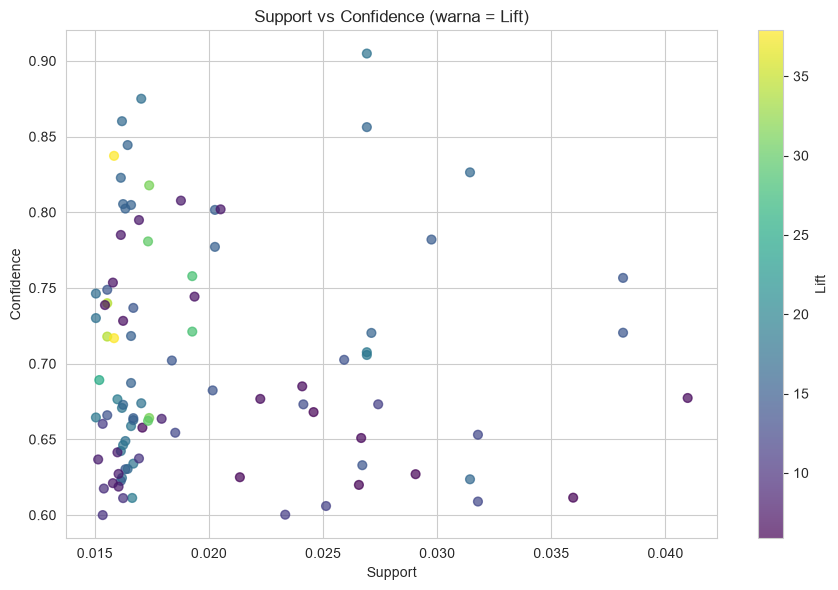

In [10]:
# Visualisasi: support vs confidence dengan warna lift
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=40, alpha=0.7)
plt.colorbar(sc, ax=ax, label="Lift")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("Support vs Confidence (warna = Lift)")
plt.tight_layout()
plt.show()


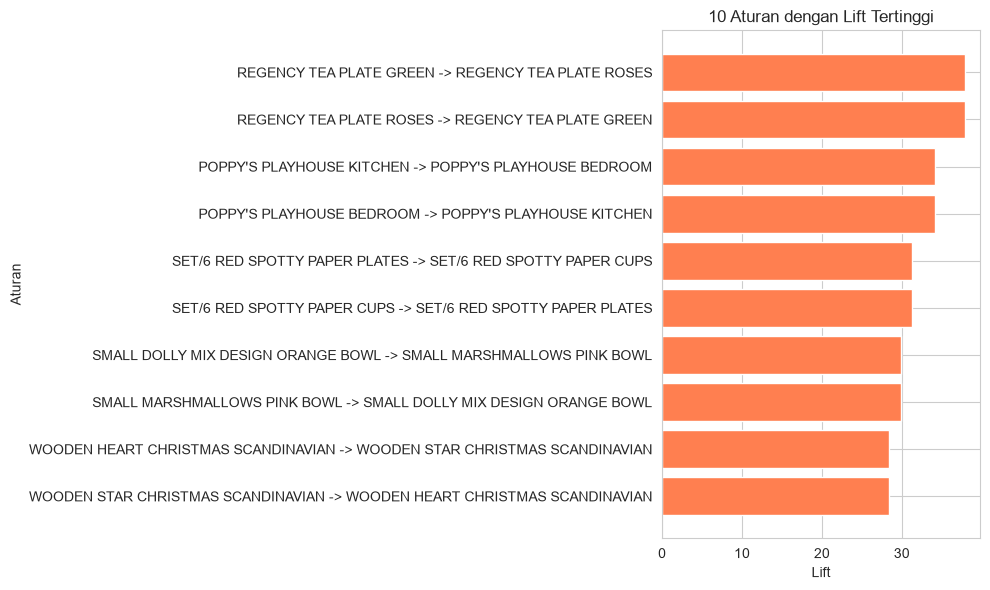

In [11]:
# Visualisasi: 10 aturan dengan lift tertinggi
top10 = rules_fmt.head(10).copy()
top10["rule"] = top10["antecedents"] + " -> " + top10["consequents"]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10["rule"][::-1], top10["lift"][::-1], color="coral")
ax.set_title("10 Aturan dengan Lift Tertinggi")
ax.set_xlabel("Lift")
ax.set_ylabel("Aturan")
plt.tight_layout()
plt.show()


### Tiga Aturan Terbaik berdasarkan Lift

Tiga aturan dengan nilai lift tertinggi dipilih untuk ditafsirkan dalam konteks bisnis ritel.


In [12]:
top3 = rules_fmt.head(3).copy()
top3


,antecedents,consequents,support,confidence,lift
0,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE ROSES,0.015842,0.837270,37.886013
1,REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.015842,0.716854,37.886013
2,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.015544,0.717890,34.173596


**Interpretasi tiga aturan terbaik:**

1. **Regency Tea Plate Roses -> Regency Tea Plate Green** (dan sebaliknya): pembeli piring teh motif mawar sangat mungkin juga membeli piring teh hijau dalam transaksi yang sama (confidence sekitar 0.72-0.84, lift ~37.9). Ini menunjukkan produk-produk dalam satu koleksi (Regency Tea Plate) cenderung dibeli bersama, kemungkinan untuk melengkapi set piring teh. Saran bisnis: tampilkan kedua warna berdekatan dan tawarkan paket "set piring teh" dengan harga bundling.

2. **Poppy's Playhouse Kitchen -> Poppy's Playhouse Bedroom** (dan sebaliknya): pembeli mainan rumah boneka bagian dapur cenderung juga membeli bagian kamar tidur (confidence ~0.72-0.74, lift ~34.2). Ini adalah pola pelengkap (complementary) pada produk mainan. Saran bisnis: bundling seluruh bagian Poppy's Playhouse dengan diskon paket, serta rekomendasi "sering dibeli bersama" di halaman produk.

3. **Set/6 Red Spotty Paper Cups -> Set/6 Red Spotty Paper Plates** (dan sebaliknya): pembeli cup kertas motif bintang merah cenderung juga membeli piring kertas motif yang sama (confidence ~0.66-0.82, lift ~31.2). Pola ini wajar karena produk pesta biasanya dibeli dalam set lengkap. Saran bisnis: buat paket "party set" (cup + plate + napkin) dan tempatkan di area yang sama.

Ketiga aturan memiliki lift jauh di atas 1, yang berarti asosiasinya kuat dan bukan sekadar kebetulan frekuensi. Namun support-nya relatif kecil (sekitar 0.015-0.018), artinya pola ini hanya berlaku pada segmen pembeli tertentu, sehingga cocok untuk strategi cross-selling tersegmentasi, bukan untuk seluruh pelanggan.


## 6. Kesimpulan

Dari analisis association rule pada dataset Online Retail:

- Setelah pembersihan, tersisa 20.136 transaksi dari 530.693 baris (penghapusan deskripsi kosong, transaksi dibatalkan, dan quantity <= 0).
- Dengan Apriori pada ambang awal (support 0.01, confidence 0.5) dihasilkan 841 aturan; setelah pengetatan (support 0.015, confidence 0.6) tersisa 94 aturan yang lebih ringkas.
- Pola yang dominan adalah produk-produk yang saling melengkapi dalam satu koleksi/famili: set piring teh Regency, bagian-bagian mainan Poppy's Playhouse, dan perlengkapan pesta bermotif bintang merah.
- Lift yang tinggi (> 1) menunjukkan asosiasi positif yang kuat, tetapi support yang relatif kecil berarti pola berlaku pada segmen tertentu sehingga cocok untuk cross-selling terarah.

Secara bisnis, hasil ini dapat dimanfaatkan untuk penataan produk (produk dalam satu koleksi ditempatkan berdekatan), bundling, dan rekomendasi "sering dibeli bersama" pada toko online.
